# Homework 4

Viraj Dua  
GitHub: VirajD24  
DSCI 552: Machine Learning

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy.special import logit
from sklearn.base import clone
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

# Keeping plots and tables easy to read.
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
SEED = 42
DATA_DIR = Path("AReM")
SERIES = ["avg_rss12", "var_rss12", "avg_rss13",
          "var_rss13", "avg_rss23", "var_rss23"]
STATISTICS = ["min", "max", "mean", "median", "std", "q1", "q3"]

## 1. Data and feature setup from HW3

The loading, train/test split, and original feature-extraction code below are copied from HW3. I then add the activity labels and segment-based features needed for HW4. The HW3 written answers are not repeated.

Datasets 1 and 2 from each bending folder and datasets 1, 2, and 3 from every other activity are test data. This leaves 69 training and 19 test recordings. The loader handles minor formatting differences; the recording with 479 readings is used as provided.

In [2]:
files = sorted(
    DATA_DIR.glob("*/*.csv"),
    key=lambda path: (path.parent.name, int(path.stem.removeprefix("dataset"))),
)

recordings = []
records = []

for path in files:
    data = pd.read_csv(
        path,
        comment="#",
        header=None,
        names=["time"] + SERIES,
        sep=r",|\s+",
        engine="python",
        usecols=range(7),
    )
    recordings.append(data[SERIES])
    records.append({
        "Activity": path.parent.name,
        "Dataset": int(path.stem.removeprefix("dataset")),
        "Readings": len(data),
    })

metadata = pd.DataFrame(records, index=range(1, len(records) + 1))
metadata.index.name = "Instance"

print(f"Activities: {metadata['Activity'].nunique()}")
print(f"Recordings: {len(recordings)}")
print("Readings per recording:", metadata["Readings"].value_counts().to_dict())
display(metadata.head())

is_bending = metadata["Activity"].isin(["bending1", "bending2"])
is_test = (is_bending & (metadata["Dataset"] <= 2)) | (
    ~is_bending & (metadata["Dataset"] <= 3)
)
metadata["Split"] = np.where(is_test, "Test", "Train")

split_counts = pd.crosstab(metadata["Activity"], metadata["Split"])
display(split_counts[["Train", "Test"]])
print(f"Total: {(~is_test).sum()} training recordings and {is_test.sum()} test recordings")

# Labels for the HW4 classifiers.
train_mask, test_mask = ~is_test, is_test
y_train = is_bending[train_mask].to_numpy(dtype=int)
y_test = is_bending[test_mask].to_numpy(dtype=int)
y_train_multi = metadata.loc[train_mask, "Activity"].to_numpy()
y_test_multi = metadata.loc[test_mask, "Activity"].to_numpy()

Activities: 7
Recordings: 88
Readings per recording: {480: 87, 479: 1}


,Activity,Dataset,Readings
Instance,,,
1,bending1,1,480
2,bending1,2,480
3,bending1,3,480
4,bending1,4,480
5,bending1,5,480


Split,Train,Test
Activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


Total: 69 training recordings and 19 test recordings


Each recording remains one observation. Dividing its six time series into `l` consecutive parts produces `42 * l` features, not additional observations. `np.array_split` keeps the parts approximately equal without discarding readings. The name `mean_1_s2`, for example, means the mean of time series 1 in segment 2.

In [3]:
feature_rows = []

for recording in recordings:
    stats = recording.describe().loc[["min", "max", "mean", "50%", "std", "25%", "75%"]]
    feature_rows.append(stats.T.to_numpy().ravel())

feature_names = [f"{stat}_{i}" for i in range(1, 7) for stat in STATISTICS]
features = pd.DataFrame(feature_rows, columns=feature_names, index=metadata.index)

train_features = features.loc[metadata["Split"] == "Train"]
test_features = features.loc[metadata["Split"] == "Test"]

print(f"Feature table: {features.shape[0]} recordings x {features.shape[1]} features")
print("Training features:", train_features.shape)
print("Test features:", test_features.shape)

# Previewing the seven features for the first time series.
display(features.iloc[:5, :7])

# Applying the same extraction to segments for HW4.
def extract_features(segments):
    rows = []
    for recording in recordings:
        blocks = []
        for positions in np.array_split(np.arange(len(recording)), segments):
            part = recording.iloc[positions]
            stats = part.describe().loc[["min", "max", "mean", "50%", "std", "25%", "75%"]]
            blocks.append(stats.T.to_numpy().ravel())
        rows.append(np.concatenate(blocks))
    names = [f"{stat}_{series}_s{segment}"
             for segment in range(1, segments + 1)
             for series in range(1, 7) for stat in STATISTICS]
    return pd.DataFrame(rows, columns=names, index=metadata.index)

# Reusing the HW3 table for l = 1 and calculate only the new segmented tables.
feature_sets = {1: features.rename(columns=lambda name: f"{name}_s1")}
feature_sets.update({l: extract_features(l) for l in range(2, 21)})
print("l = 1:", feature_sets[1].shape, " | l = 20:", feature_sets[20].shape)

Feature table: 88 recordings x 42 features
Training features: (69, 42)
Test features: (19, 42)


,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1
Instance,,,,,,,
1,37.25,45.00,40.6248,40.50,1.4770,39.25,42.00
2,38.00,45.67,42.8128,42.50,1.4355,42.00,43.67
3,35.00,47.40,43.9545,44.33,1.5588,43.00,45.00
4,33.00,47.75,42.1798,43.50,3.6707,39.15,45.00
5,33.00,45.75,41.6781,41.75,2.2435,41.33,42.75


l = 1: (88, 42)  | l = 20: (88, 840)


## 2. Time Series Classification Part 2

### (a) Binary classification using logistic regression

#### i. Scatter plots before splitting

I keep the three feature types chosen in HW3: mean, maximum, and standard deviation. These plots use only training recordings and time series 1, 2, and 6. Bending includes both bending activities. I group the scatter plots by feature type to keep them readable.

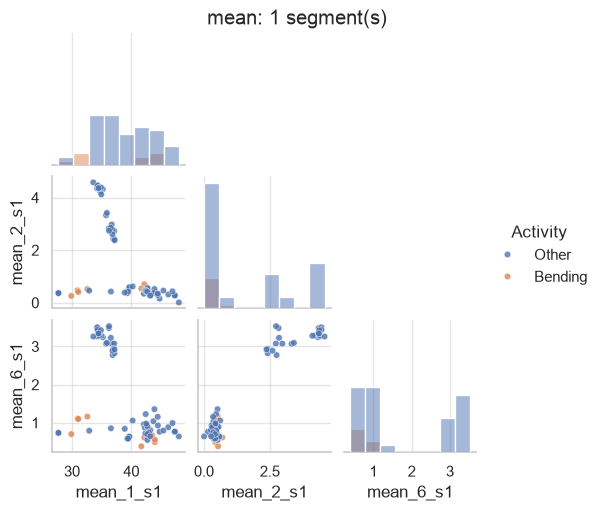

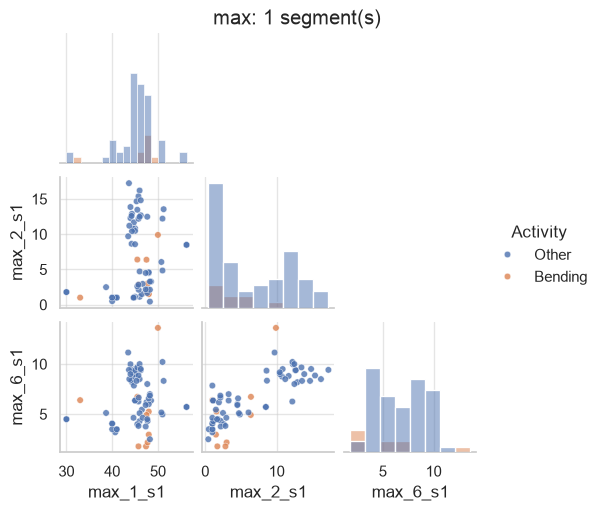

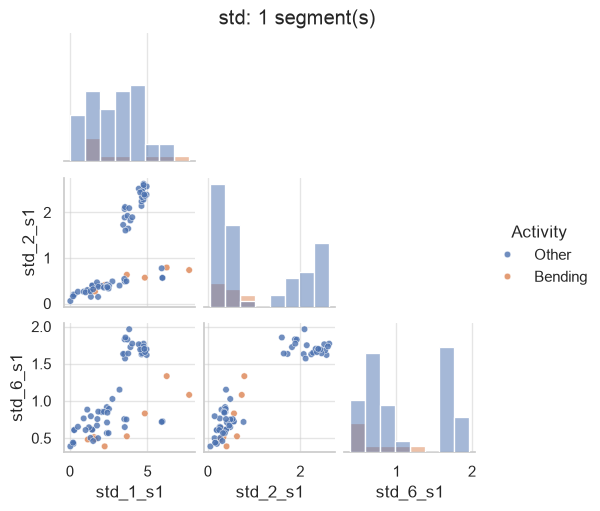

In [4]:
def plot_features(segments):
    for statistic in ["mean", "max", "std"]:
        columns = [f"{statistic}_{series}_s{segment}"
                   for segment in range(1, segments + 1) for series in [1, 2, 6]]
        plot_data = feature_sets[segments].loc[train_mask, columns].copy()
        plot_data["Activity"] = np.where(y_train == 1, "Bending", "Other")
        grid = sns.pairplot(plot_data, vars=columns, hue="Activity",
                            hue_order=["Other", "Bending"], corner=True,
                            diag_kind="hist", height=1.65,
                            plot_kws={"s": 22, "alpha": 0.8})
        grid.figure.suptitle(f"{statistic}: {segments} segment(s)", y=1.02)
        plt.show()

plot_features(1)

#### ii. Scatter plots after splitting into two parts

I extract the same features separately from each half of time series 1, 2, and 6. The plots now contain six features per statistic instead of three.

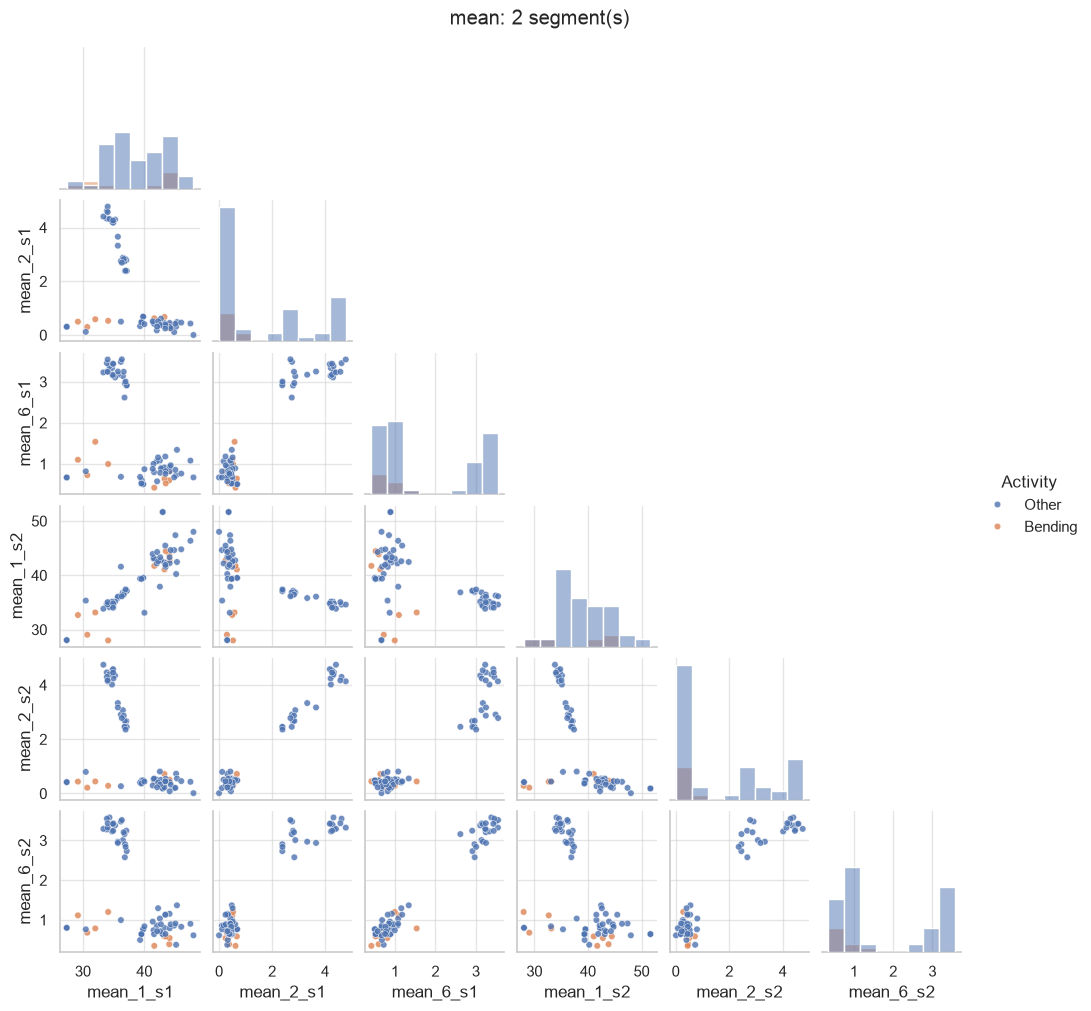

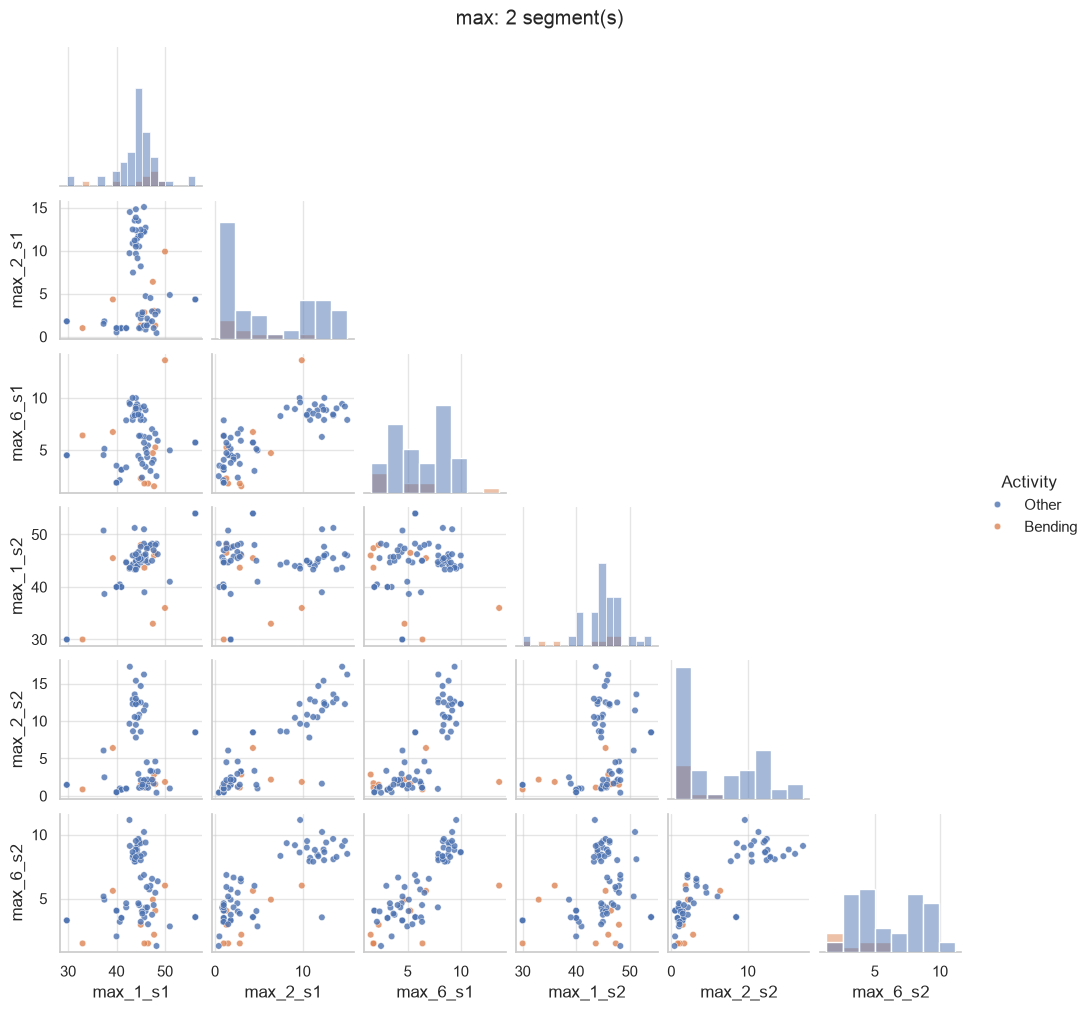

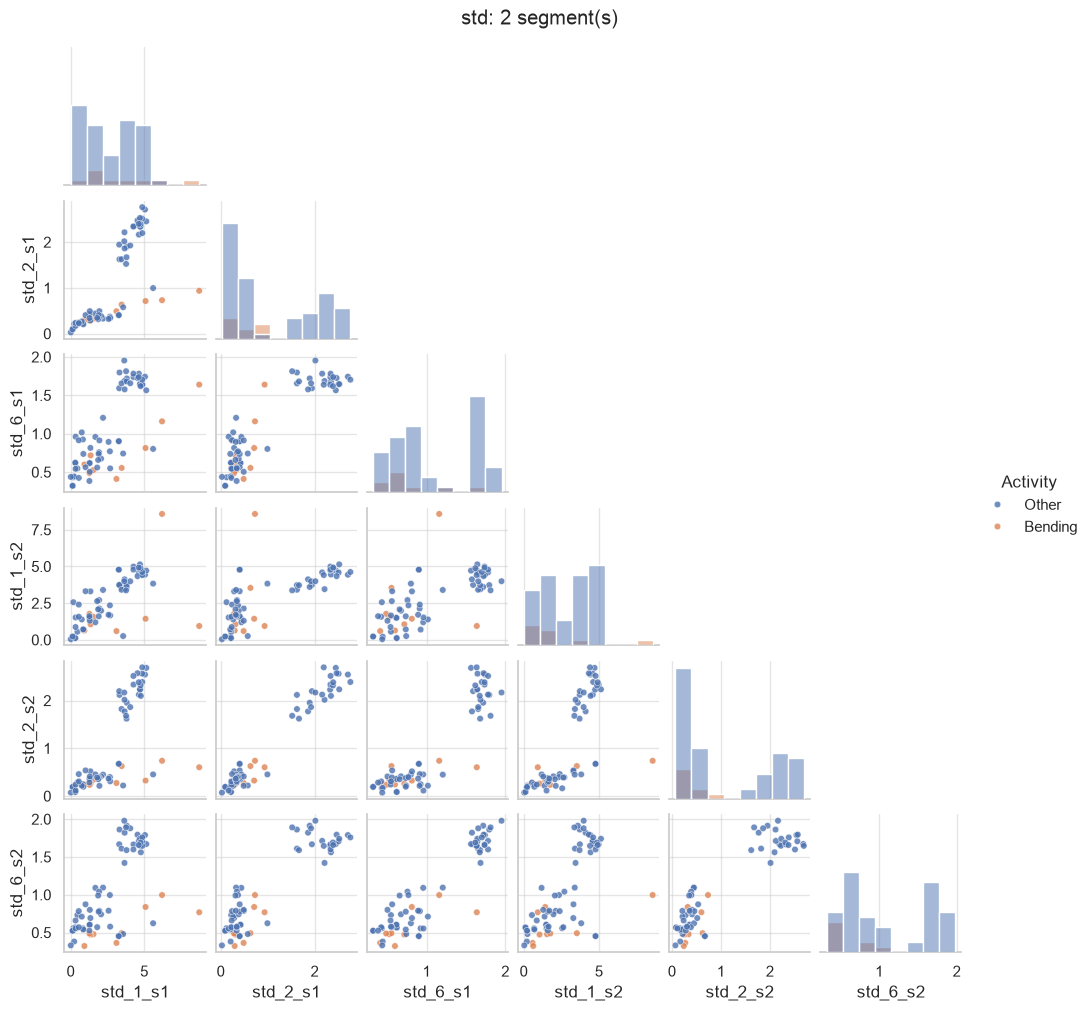

In [5]:
plot_features(2)

Splitting each time series into two halves does not produce a considerable overall change in the scatter plots. Some feature pairs distinguish bending from other activities, but overlap remains. There is no obvious large improvement in visual separation compared with the original plots.

#### iii. Choose the number of segments and features

For each `l` from 1 through 20, I use RFECV with five-fold stratified cross-validation to choose the number of features `p`. RFE removes one feature at a time, while stratification keeps the bending/other proportions similar across folds. I select the pair with the highest mean CV accuracy; ties favor fewer segments, then fewer features.

Scaling and feature selection use only the training portion of each fold. Doing these steps on the full training set before cross-validation would let validation data influence the model and could make the scores overly optimistic. The test set is kept separate until final evaluation.

I use `C=1e6` to make the L2 penalty negligible.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
plain_logit = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(C=1e6, solver="liblinear", max_iter=2000,
                                  random_state=SEED)),
])
rfe_models, rfe_rows = {}, []

for l in range(1, 21):
    selector = RFECV(plain_logit, step=1, cv=cv, scoring="accuracy",
                     importance_getter="named_steps.logit.coef_")
    selector.fit(feature_sets[l].loc[train_mask], y_train)
    rfe_models[l] = selector
    rfe_rows.append({"l": l, "Features": selector.n_features_,
                     "CV accuracy": selector.cv_results_["mean_test_score"].max()})

rfe_results = pd.DataFrame(rfe_rows)
best_rfe = rfe_results.sort_values(["CV accuracy", "l", "Features"],
                                   ascending=[False, True, True]).iloc[0]
rfe_l = int(best_rfe["l"])
rfe_model = rfe_models[rfe_l]
X_rfe_train = feature_sets[rfe_l].loc[train_mask]
X_rfe_test = feature_sets[rfe_l].loc[test_mask]
display(rfe_results)
print(f"Selected: l = {rfe_l}, p = {rfe_model.n_features_}, "
      f"CV accuracy = {best_rfe['CV accuracy']:.4f}")

,l,Features,CV accuracy
0,1,13,0.9714
1,2,3,0.9571
2,3,6,0.9286
3,4,16,0.9571
4,5,6,0.9571
5,6,5,0.9714
6,7,6,0.9418
7,8,56,0.9429
8,9,348,0.9571
9,10,16,0.9714


Selected: l = 20, p = 6, CV accuracy = 1.0000


#### iv. Training confusion matrix, ROC, coefficients, and p-values

Bending is the positive class (1); other activities are class 0. Confusion-matrix rows are actual classes and columns are predicted classes. ROC uses predicted bending probabilities; classification uses the usual 0.5 threshold.

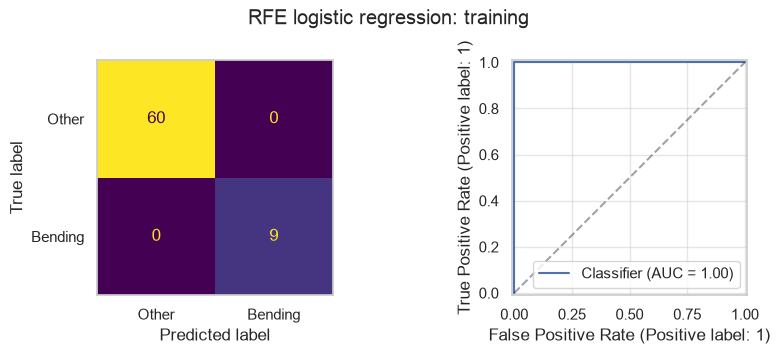

RFE logistic regression: training: accuracy = 1.0000, AUC = 1.0000
Complete separation: ordinary maximum-likelihood p-values are undefined.


,Coefficient,p-value
Intercept,-15.7590,NaN
mean_5_s3,6.0053,NaN
median_5_s3,4.0144,NaN
q1_5_s3,6.0805,NaN
q3_1_s12,-5.0295,NaN
median_4_s15,-1.9934,NaN
std_5_s19,-4.7650,NaN


Coefficients use standardized features; NaN means no valid ordinary p-value.


In [7]:
def binary_report(y, probability, title):
    prediction = (probability >= 0.5).astype(int)
    accuracy = accuracy_score(y, prediction)
    auc = roc_auc_score(y, probability)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    ConfusionMatrixDisplay.from_predictions(
        y, prediction, labels=[0, 1], display_labels=["Other", "Bending"],
        colorbar=False, ax=axes[0])
    axes[0].grid(False)
    RocCurveDisplay.from_predictions(y, probability, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    print(f"{title}: accuracy = {accuracy:.4f}, AUC = {auc:.4f}")
    return accuracy, auc

rfe_train_probability = rfe_model.predict_proba(X_rfe_train)[:, 1]
rfe_train_accuracy, rfe_train_auc = binary_report(
    y_train, rfe_train_probability, "RFE logistic regression: training")

selected_names = X_rfe_train.columns[rfe_model.support_]
fitted_logit = rfe_model.estimator_.named_steps["logit"]
coefficients = pd.DataFrame({
    "Coefficient": np.r_[fitted_logit.intercept_, fitted_logit.coef_.ravel()],
    "p-value": np.nan,
}, index=["Intercept"] + selected_names.tolist())

# A positive margin for every recording proves that a separating line exists.
signed_margin = (2 * y_train - 1) * rfe_model.decision_function(X_rfe_train)
separated = bool((signed_margin > 0).all())
if separated:
    print("Complete separation: ordinary maximum-likelihood p-values are undefined.")
else:
    scaled = rfe_model.estimator_.named_steps["scale"].transform(
        X_rfe_train[selected_names])
    inference = sm.GLM(y_train, sm.add_constant(scaled, has_constant="add"),
                       family=sm.families.Binomial()).fit()
    coefficients["Unpenalized GLM coefficient"] = inference.params
    coefficients["p-value"] = inference.pvalues

display(coefficients)
print("Coefficients use standardized features; NaN means no valid ordinary p-value.")

The table reports coefficients from the weakly regularized prediction model (`C=1e6`). The selected features completely separate the training classes, so ordinary unpenalized coefficient estimates do not settle at finite values and the usual p-values are not valid. I therefore mark the p-values as `NaN` to indicate that they cannot be reliably estimated for this fit.

#### v. Evaluate on the test set

I use the same number of segments, selected features, and fitted scaler as in training. The test data are not used to choose any of these settings.

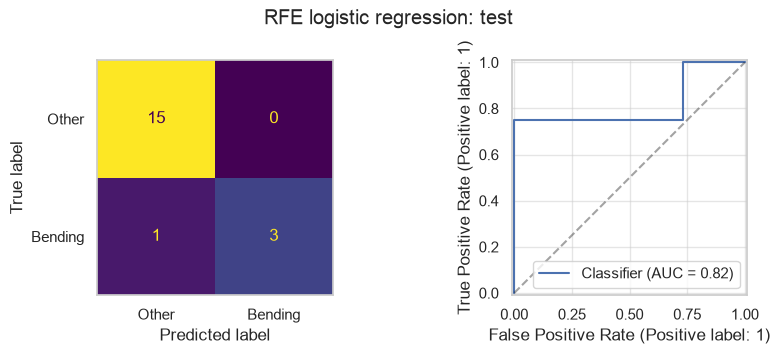

RFE logistic regression: test: accuracy = 0.9474, AUC = 0.8167


,Accuracy
Best five-fold CV,1.0000
Test,0.9474


Test minus CV accuracy: -0.0526


In [8]:
rfe_test_probability = rfe_model.predict_proba(X_rfe_test)[:, 1]
rfe_test_accuracy, rfe_test_auc = binary_report(
    y_test, rfe_test_probability, "RFE logistic regression: test")
display(pd.DataFrame({"Accuracy": [best_rfe["CV accuracy"], rfe_test_accuracy]},
                     index=["Best five-fold CV", "Test"]))
print(f"Test minus CV accuracy: {rfe_test_accuracy - best_rfe['CV accuracy']:+.4f}")

#### vi. Separation and coefficient stability

Yes. The selected features completely separate bending from other activities in the training set. Without regularization, the coefficients can keep growing as predicted probabilities approach 0 or 1, rather than settling at finite values. This makes coefficient estimation unstable and ordinary p-values invalid, even though training classification is perfect.

#### vii. Class imbalance and case-control sampling

There are 9 bending and 60 other training recordings, so the classes are imbalanced even if the classifier makes few errors. I keep all nine bending recordings and randomly sample nine other recordings without replacement. Feature selection remains the one chosen in part (iii).

As in the lecture's case-control example, I correct the fitted intercept by adding `logit(original proportion) - logit(sampled proportion)`. I estimate the original proportion from the full training set (9/69); the true population proportion is not supplied. Evaluation uses the original, unbalanced training and test sets, not just the balanced sample.

Training class counts: {'Other': 60, 'Bending': 9}
Balanced sample: 9 bending, 9 other
Intercept adjustment: -1.8971


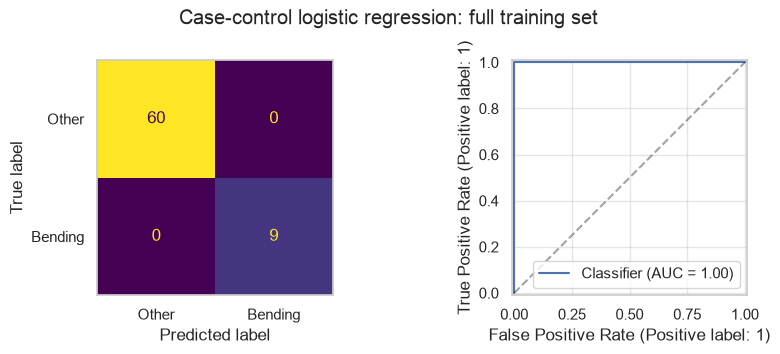

Case-control logistic regression: full training set: accuracy = 1.0000, AUC = 1.0000


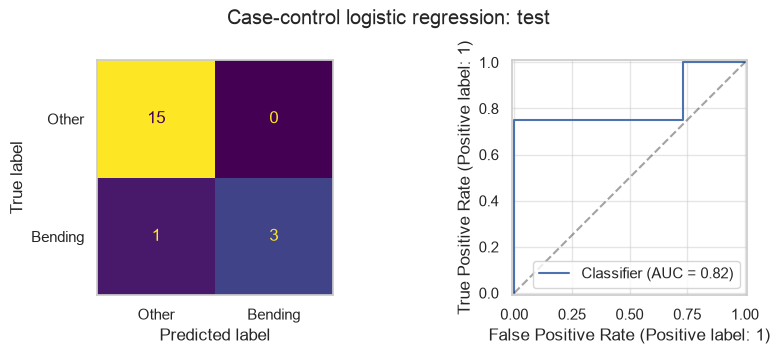

Case-control logistic regression: test: accuracy = 0.9474, AUC = 0.8167


In [9]:
print("Training class counts:", {"Other": int((y_train == 0).sum()),
                                  "Bending": int((y_train == 1).sum())})
rng = np.random.default_rng(SEED)
cases = np.flatnonzero(y_train == 1)
controls = rng.choice(np.flatnonzero(y_train == 0), size=len(cases), replace=False)
sample = np.r_[cases, controls]

case_control_model = clone(rfe_model.estimator_)
case_control_model.fit(X_rfe_train[selected_names].iloc[sample], y_train[sample])
original_proportion = y_train.mean()
sampled_proportion = y_train[sample].mean()
intercept_adjustment = logit(original_proportion) - logit(sampled_proportion)
case_control_model.named_steps["logit"].intercept_ += intercept_adjustment
print(f"Balanced sample: {len(cases)} bending, {len(controls)} other")
print(f"Intercept adjustment: {intercept_adjustment:.4f}")

cc_train_accuracy, cc_train_auc = binary_report(
    y_train, case_control_model.predict_proba(X_rfe_train[selected_names])[:, 1],
    "Case-control logistic regression: full training set")
cc_test_accuracy, cc_test_auc = binary_report(
    y_test, case_control_model.predict_proba(X_rfe_test[selected_names])[:, 1],
    "Case-control logistic regression: test")

Balancing the classes discards many other-activity recordings, so it does not necessarily improve test accuracy. The intercept correction adjusts predicted probabilities to reflect the original class proportions. For the same fitted model, this adjustment preserves the ordering of predictions, so ROC and AUC remain unchanged. Complete separation can still make the coefficients unstable.

### (b) Binary classification using L1-penalized logistic regression

#### i. Choose segments and penalty strength

I search all `l` values from 1 through 20 and `C` values 0.01, 0.1, 1, and 10 using the same five-fold splits. Smaller `C` means a stronger penalty. Scaling is fitted inside each training fold. L1 sets some coefficients to zero, so a separate RFE step is unnecessary. I use `liblinear` for binary L1 logistic regression.

The search below is also reused for the multiclass and Naive Bayes models. It fits each final candidate on all training recordings, but selects settings using only CV accuracy. Ties favor smaller `l`; within each grid, smaller parameter values are tried first.

,l,CV accuracy,C
0,1,0.9571,1
1,2,0.9571,1
2,3,0.9571,1
3,4,0.9571,1
4,5,0.9275,10
5,6,0.9429,1
6,7,0.9275,1
7,8,0.9286,1
8,9,0.9275,1
9,10,0.9286,10


Selected: l = 19, C = 1


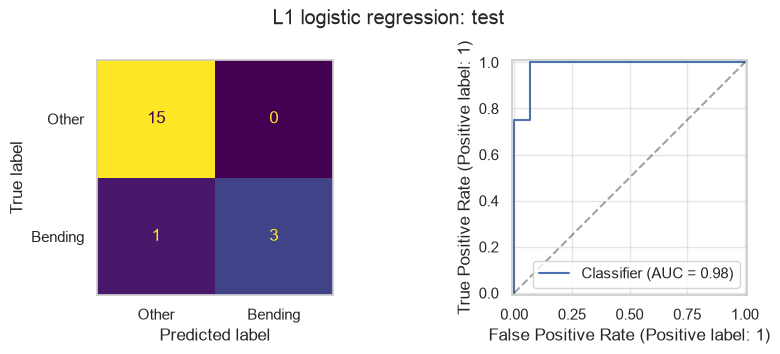

L1 logistic regression: test: accuracy = 0.9474, AUC = 0.9833
Nonzero features: 10


In [10]:
C_GRID = [0.01, 0.1, 1, 10]

def search_segments(model, parameters, labels, folds):
    searches, rows = {}, []
    for l in range(1, 21):
        search = GridSearchCV(model, parameters, cv=folds, scoring="accuracy",
                               error_score="raise")
        search.fit(feature_sets[l].loc[train_mask], labels)
        searches[l] = search
        rows.append({"l": l, "CV accuracy": search.best_score_,
                     **search.best_params_})
    results = pd.DataFrame(rows)
    best = results.sort_values(["CV accuracy", "l"], ascending=[False, True]).iloc[0]
    l = int(best["l"])
    return l, searches[l].best_estimator_, best, results

l1_binary = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=5000,
                                  random_state=SEED)),
])
l1_l, l1_model, l1_best, l1_results = search_segments(
    l1_binary, {"logit__C": C_GRID}, y_train, cv)
display(l1_results.rename(columns={"logit__C": "C"}))
print(f"Selected: l = {l1_l}, C = {l1_best['logit__C']:g}")
l1_test_probability = l1_model.predict_proba(feature_sets[l1_l].loc[test_mask])[:, 1]
l1_test_accuracy, l1_test_auc = binary_report(
    y_test, l1_test_probability, "L1 logistic regression: test")
print("Nonzero features:", np.count_nonzero(l1_model.named_steps["logit"].coef_))

#### ii. Compare with backward selection

Both models achieve 94.74% test accuracy. L1 has the higher test AUC (0.9833 versus 0.8167), although RFE has slightly higher cross-validation accuracy.

L1 is easier to implement because it selects features while fitting the model by setting some coefficients to zero. RFE repeatedly fits the model while removing features, so it requires more computation. In this run, L1 provides better test AUC with a simpler feature-selection procedure.

In [11]:
binary_comparison = pd.DataFrame([
    {"Model": "RFE logistic", "l": rfe_l, "CV accuracy": best_rfe["CV accuracy"],
     "Test accuracy": rfe_test_accuracy, "Test AUC": rfe_test_auc},
    {"Model": "L1 logistic", "l": l1_l, "CV accuracy": l1_best["CV accuracy"],
     "Test accuracy": l1_test_accuracy, "Test AUC": l1_test_auc},
]).set_index("Model")
display(binary_comparison)
if np.isclose(rfe_test_accuracy, l1_test_accuracy):
    print("The models tie on test accuracy; compare their AUC values above as well.")
else:
    print("Higher test accuracy:", binary_comparison["Test accuracy"].idxmax())

,l,CV accuracy,Test accuracy,Test AUC
Model,,,,
RFE logistic,20,1.0000,0.9474,0.8167
L1 logistic,19,0.9857,0.9474,0.9833


The models tie on test accuracy; compare their AUC values above as well.


### (c) Multiclass classification

#### i. L1-penalized multinomial logistic regression

I fit an L1-penalized multinomial logistic model to classify all seven activities. Using the `saga` solver and five-fold stratified cross-validation, I search `l=1,...,20` and `C` values 0.01, 0.1, 1, and 10.

There are only four `bending2` training recordings, so one validation fold has none. Every training fold still contains all seven classes, and validation accuracy can still be calculated.

In the confusion matrix, rows are actual activities and columns are predictions. Each ROC curve compares one activity against all others. Macro AUC averages the seven class-specific AUC values equally.

Sources: [stratified cross-validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html) and [multiclass ROC](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html).

In [12]:
# The minority-class limitation is explained above; reuse the same folds for all models.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The least populated class.*", category=UserWarning)
    multi_folds = list(cv.split(feature_sets[1].loc[train_mask], y_train_multi))

multinomial = Pipeline([
    ("scale", StandardScaler()),
    ("logit", LogisticRegression(l1_ratio=1, solver="saga", max_iter=20000,
                                  tol=0.001, random_state=SEED)),
])
multi_l, multi_model, multi_best, multi_results = search_segments(
    multinomial, {"logit__C": C_GRID}, y_train_multi, multi_folds)
display(multi_results.rename(columns={"logit__C": "C"}))
print(f"Selected: l = {multi_l}, C = {multi_best['logit__C']:g}")

,l,CV accuracy,C
0,1,0.9000,1
1,2,0.8692,10
2,3,0.8714,10
3,4,0.8714,10
4,5,0.8714,10
5,6,0.8560,10
6,7,0.8560,10
7,8,0.8264,10
8,9,0.8714,10
9,10,0.8275,10


Selected: l = 1, C = 1


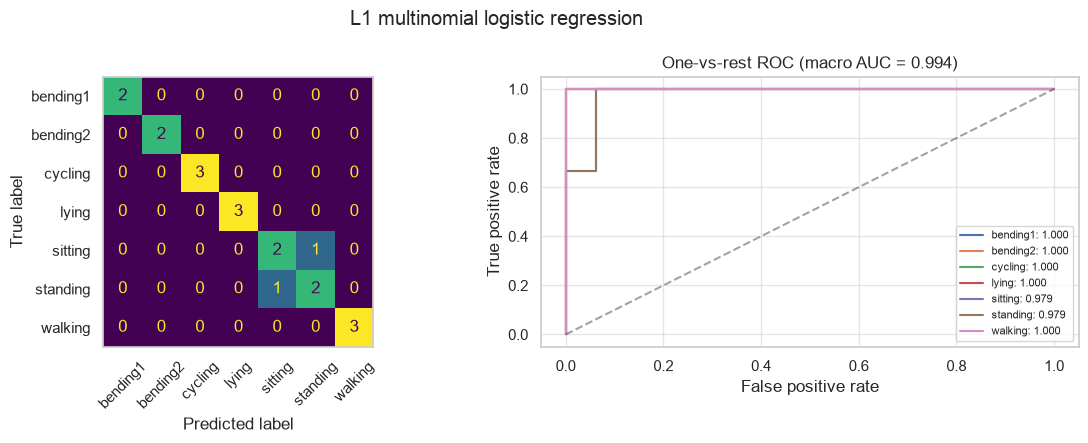

L1 multinomial logistic regression: test error = 0.1053, macro AUC = 0.9940


In [13]:
def multiclass_report(model, segments, title):
    X_test = feature_sets[segments].loc[test_mask]
    classes = model.classes_
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)
    accuracy = accuracy_score(y_test_multi, prediction)
    auc = roc_auc_score(y_test_multi, probability, labels=classes,
                        multi_class="ovr", average="macro")
    actual = label_binarize(y_test_multi, classes=classes)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay.from_predictions(
        y_test_multi, prediction, labels=classes, xticks_rotation=45,
        colorbar=False, ax=axes[0])
    axes[0].grid(False)
    for i, activity in enumerate(classes):
        fpr, tpr, _ = roc_curve(actual[:, i], probability[:, i])
        activity_auc = roc_auc_score(actual[:, i], probability[:, i])
        axes[1].plot(fpr, tpr, label=f"{activity}: {activity_auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate",
                title=f"One-vs-rest ROC (macro AUC = {auc:.3f})")
    axes[1].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    print(f"{title}: test error = {1 - accuracy:.4f}, macro AUC = {auc:.4f}")
    return accuracy, auc

multi_accuracy, multi_auc = multiclass_report(
    multi_model, multi_l, "L1 multinomial logistic regression")

#### ii. Gaussian and Multinomial Naive Bayes

For both models, I choose `l` and the smoothing parameter using the same five-fold cross-validation splits as the multiclass logistic model. I use unscaled features so Multinomial NB receives only nonnegative values.

Gaussian NB assumes a normal distribution for each feature within an activity. Multinomial NB is designed for count-like data, so its assumptions are less natural for these continuous feature summaries.

Gaussian NB: l = 1, var_smoothing = 1e-05
Multinomial NB: l = 1, alpha = 0.01


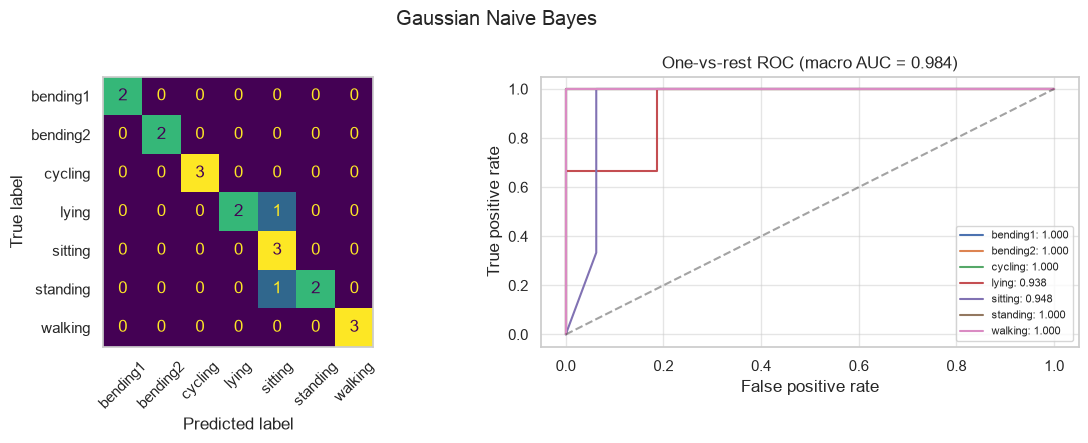

Gaussian Naive Bayes: test error = 0.1053, macro AUC = 0.9836


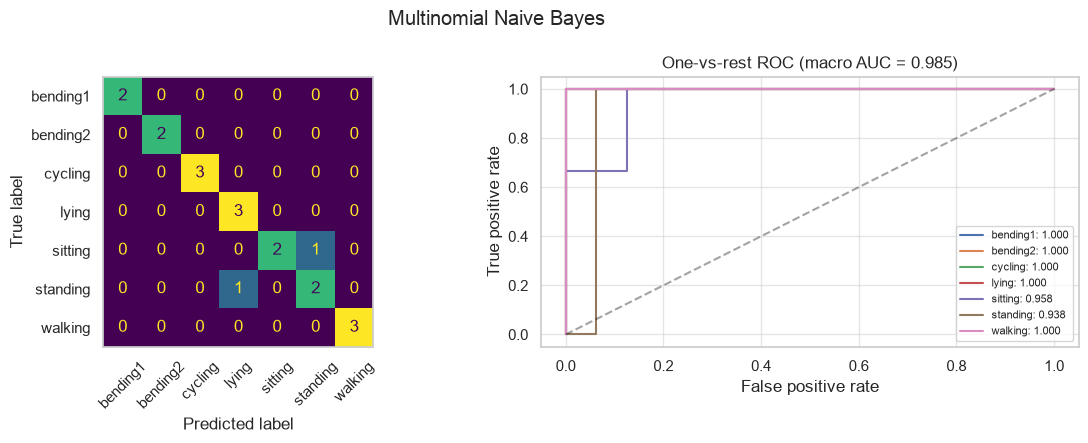

Multinomial Naive Bayes: test error = 0.1053, macro AUC = 0.9851


In [14]:
gnb_l, gnb_model, gnb_best, gnb_results = search_segments(
    GaussianNB(), {"var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5]},
    y_train_multi, multi_folds)
mnb_l, mnb_model, mnb_best, mnb_results = search_segments(
    MultinomialNB(), {"alpha": [0.01, 0.1, 1, 10]},
    y_train_multi, multi_folds)
print(f"Gaussian NB: l = {gnb_l}, var_smoothing = {gnb_best['var_smoothing']:g}")
print(f"Multinomial NB: l = {mnb_l}, alpha = {mnb_best['alpha']:g}")
gnb_accuracy, gnb_auc = multiclass_report(gnb_model, gnb_l, "Gaussian Naive Bayes")
mnb_accuracy, mnb_auc = multiclass_report(mnb_model, mnb_l, "Multinomial Naive Bayes")

#### iii. Compare multiclass methods

All three methods tie on test error in this run. L1 multinomial logistic regression has the highest macro AUC, so I would favor it here when considering both accuracy and probability rankings. With only 19 test recordings, one mistake changes accuracy by about 5.26 percentage points, so this is not strong evidence that it is always better. These test comparisons are descriptive; they are not used to retune any model.

In [15]:
multiclass_comparison = pd.DataFrame([
    {"Model": "L1 multinomial logistic", "l": multi_l,
     "CV accuracy": multi_best["CV accuracy"], "Test accuracy": multi_accuracy,
     "Test error": 1 - multi_accuracy, "Macro AUC": multi_auc},
    {"Model": "Gaussian NB", "l": gnb_l,
     "CV accuracy": gnb_best["CV accuracy"], "Test accuracy": gnb_accuracy,
     "Test error": 1 - gnb_accuracy, "Macro AUC": gnb_auc},
    {"Model": "Multinomial NB", "l": mnb_l,
     "CV accuracy": mnb_best["CV accuracy"], "Test accuracy": mnb_accuracy,
     "Test error": 1 - mnb_accuracy, "Macro AUC": mnb_auc},
]).set_index("Model")
display(multiclass_comparison)
best_error = multiclass_comparison["Test error"].min()
winners = multiclass_comparison.index[np.isclose(multiclass_comparison["Test error"], best_error)]
print("Lowest test error:", ", ".join(winners))

,l,CV accuracy,Test accuracy,Test error,Macro AUC
Model,,,,,
L1 multinomial logistic,1,0.9000,0.8947,0.1053,0.9940
Gaussian NB,1,0.8857,0.8947,0.1053,0.9836
Multinomial NB,1,0.8857,0.8947,0.1053,0.9851


Lowest test error: L1 multinomial logistic, Gaussian NB, Multinomial NB


## 3. ISLR 4.8.3

For class k, Bayes' rule assigns x to the class maximizing its prior probability times its normal density. Taking logs and dropping terms that are the same for every class gives:

$$
\delta_k(x) = \log \pi_k - \log \sigma_k
              - \frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the square:

$$
\delta_k(x) = -\frac{x^2}{2\sigma_k^2}
              + \frac{\mu_k x}{\sigma_k^2}
              - \frac{\mu_k^2}{2\sigma_k^2}
              - \log \sigma_k + \log \pi_k.
$$

The boundary between classes k and j occurs where their scores are equal. If their variances differ, the coefficient of x squared in the difference is nonzero, so this is a quadratic equation in x. Thus the boundary is generally quadratic, not linear. If the variances are equal, the squared terms cancel and the boundary reduces to a linear one.

## 4. ISLR 4.8.7

Let Y mean that a company issues a dividend. The given quantities are:

- P(Y) = 0.8 and P(no dividend) = 0.2.
- X given Y is normal with mean 10 and variance 36.
- X given no dividend is normal with mean 0 and variance 36.

Using Bayes' rule at X = 4, the common normal-density factor cancels:

$$
P(Y\mid X=4)
= \frac{0.8\exp(-(4-10)^2/72)}
       {0.8\exp(-(4-10)^2/72)+0.2\exp(-(4-0)^2/72)}
\approx 0.7519.
$$

The probability of issuing a dividend is about **75.2%**, so the prediction at a 0.5 threshold is **Yes**.